# Artificial Intelligence in Health Care - Exercise 2
## Convolutional Neural Networks for Image Classification

Mitglieder: Elbischger Selina, Krauss Marco
Jahrgang: EHT25

Das Ziel der Übung ist es ein CNN (Convolusional neural Network) zu trainieren um damit verschiedene histologische Bilder von Darmgewebe der passenden Kategorie (Darmschleimhaut, Tumorgewebe, Muskel, etc. ) zuordnen zu können.

In [6]:
#Imports and Configs
import os
os.environ["KERAS_BACKEND"] = "torch"

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

#Datensatzimporte
#%pip install medmnist  #install package medmnist
from medmnist import INFO

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
#print("keras", keras.__version__, "| backend", keras.backend.backend())

### 1 Data Pre-Processing and Partitioning [2P]
Der Datensatz ist bereits in Trainings- Validierungs- und Testsets aufgeteilt. Die Bilder und Labels werden geladen. Im ersten Schritt verschaffen wir uns einen Überblick über den Datensatz. Hierfür wird für jede der 9 Klassen ein Bild mit dem passenden Label angezeigt. Weiters wird:  
* One-Hot-Encoding der Klassenlabels
* Pixelwerte von 0-255 auf 0-1
* Klassenverteilung ermitteln

Für die Zuordnung der nummerischen Label 0-8 zu den Klassen recherchierten wir die Datensatzbeschreibung und fanden diese in folgendem Repo: https://github.com/MedMNIST/MedMNIST/blob/main/medmnist/info.py .  

<center>

| Label | Klasse |
| :---: | :--- |
| 0 | Fettgewebe |
| 1 | Hintergrund |
| 2 | Debris |
| 3 | Lymphozyten |
| 4 | Schleim |
| 5 | Glatte Muskulatur |
| 6 | normale Darmschleimhaut |
| 7 | Tumorassoziiertes Stroma |
| 8 | Kolorektales Adenokarzinom-Epithel |

</center>

Keys =  ['x_train', 'x_val', 'x_test', 'y_train', 'y_val', 'y_test']
Label 0: adipose
Label 1: background
Label 2: debris
Label 3: lymphocytes
Label 4: mucus
Label 5: smooth muscle
Label 6: normal colon mucosa
Label 7: cancer-associated stroma
Label 8: colorectal adenocarcinoma epithelium


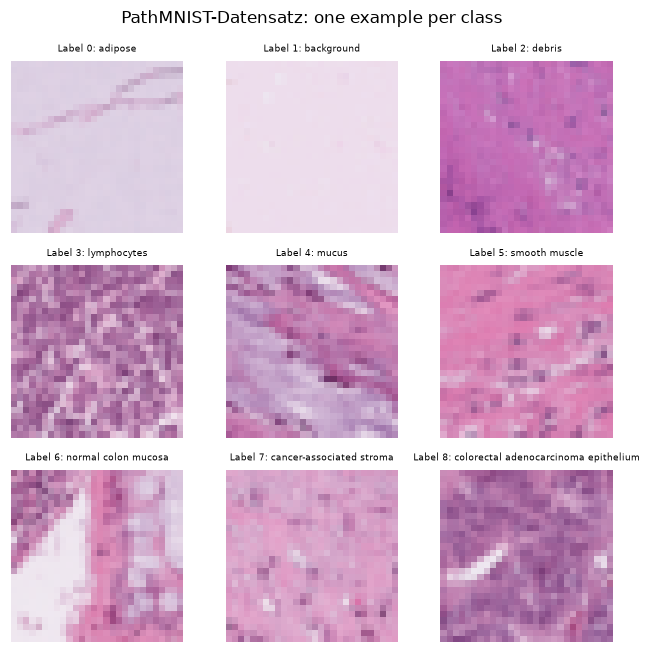

In [7]:
#Datensatz laden und Ausgabe der Keys
path = np.load('C:\\Users\\selin\\Documents\\GitLab\\KIGW\\data\\path_train.npz')
print("Keys = ", list(path.keys()))

#Aufteilen in Trainings-, Validierungs- und Testdaten
x_train, y_train = path['x_train'], path['y_train']
x_val, y_val = path['x_val'], path['y_val']
x_test, y_test = path['x_test'], path['y_test']

# Zuordnung der Labels zu den Klassen
class_labels = INFO['pathmnist']['label']
#display(len(class_labels))  # Anzahl der Klassen

for label, class_name in class_labels.items():
    print(f"Label {label}: {class_name}")

#Darstellung eines Bildes pro Klasse
labels = y_train.ravel()        # Eindimensionales Array
fig, axes = plt.subplots(3, 3, figsize=(6, 6))
for i, ax in enumerate(axes.ravel()):       #axes.ravel() gibt ein eindimensionales Array der Achsen zurück -> weil die sind derzeit 3x3 angeordnet
    image_index = np.where(labels == i)[0][0]  # Index des ersten Bildes der Klasse i
    ax.imshow(x_train[image_index], cmap='gray')    # Darstellung des Bildes
    ax.set_title(f"Label {i}: {class_labels[str(i)]}", fontsize=6)  # Titel mit Label und Klassenname   #str(1) weil die keys in class_labels strings sind
    ax.axis('off')    # Achsen ausblenden
fig.suptitle("PathMNIST-Datensatz: one example per class", fontsize=11)
plt.tight_layout()
plt.show()

In [8]:
#One-hot-Encoding der Labels
y_train_oh = keras.utils.to_categorical(y_train, num_classes=len(class_labels))
y_val_oh = keras.utils.to_categorical(y_val, num_classes=len(class_labels))
y_test_oh = keras.utils.to_categorical(y_test, num_classes=len(class_labels))

#Skalierung der Bilder auf den Wertebereich [0, 1] -> wichtig für NN zum lernen ; Bildinformation bleibt erhalen weil 128 ist dann irgendein Kommawert 0,5xy
x_train = x_train.astype('float32') / 255.0
x_val = x_val.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

#Klassenverteilung des Trainingsdatensatzes
classes, counts = np.unique(y_train.ravel(), return_counts=True)  #eindeutigen Klassen und Anzahl der Bilder pro Klasse

#Übersicht in Dataframe
class_distribution = pd.DataFrame({'Klasse/Label': classes, 
                                   'Anzahl Bilder': counts,
                                   'prozentueller Anteil': (counts / len(y_train) * 100).round(2)})
display(class_distribution)

,Klasse/Label,Anzahl Bilder,prozentueller Anteil
0,0,9366,10.41
1,1,9509,10.57
2,2,10360,11.51
3,3,10401,11.56
4,4,8006,8.90
5,5,12182,13.54
6,6,7886,8.76
7,7,9401,10.45
8,8,12885,14.32


### 2 Fully-Connected Neural Network [3P]
Als Basline zum vergleichen wird ein Fully connected neural Network mit folgender Netzwerkarchitektur gebaut:  
- 3 hidden layers (1024, 512 and 128)
- RELU Funktion
- 1 outputlayer mit softmax-Aktivierungsfunktion

Training mit categorical-cross entropy, early stopping und adam optimizer mit α = 0.001; eventuell Dropout.

In [9]:
#Fuktion zum Kompilieren, Trainieren und Evaluieren des Modells inkl. Ausgabe
def train_model(model, epochs=25, tag=""):
    model.compile(optimizer=keras.optimizers.Adam(0.001),
                  loss=keras.losses.CategoricalCrossentropy(),
                  metrics=[keras.metrics.CategoricalAccuracy(name="acc")])

    #Early Stopping -> verhinder Overfitting -> validierunsfehler überwachen ; wenn nach 5 Epochen keine Verbesserung -> abbruch & besten Gewichte
    early_stop = keras.callbacks.EarlyStopping(monitor="val_acc", 
                                               mode="max",
                                               patience=5, 
                                               restore_best_weights=True)

    #Model trainieren
    h = model.fit(x_train, y_train_oh,                      #Trainingsdaten und korrekte Labels
                  validation_data=(x_val, y_val_oh),        #Validierungsdaten und korrekte Labels
                  epochs=epochs,
                  batch_size=128,         #Anzahl der Bilder für Berechnung des Gradienten/Gewicht pro Schritt
                  verbose=0, 
                  callbacks=[early_stop])
    
    
    prob = model.predict(x_test, batch_size=128) # Wahrscheinlichkeiten für jede Klasse für jedes Testbild
    pred = prob.argmax(axis=1)     # Index der Klasse mit der höchsten Wahrscheinlichkeit für jedes Testbild -> liefert eindimensionales Array
    
    test_label = y_test.ravel()  # Eindimensionales Array der Testlabels
    acc = accuracy_score(test_label, pred)      #korrekt vorhergesagte Labels
    auc = roc_auc_score(test_label, prob, multi_class="ovr", average="macro") #ovr=one-vs-rest, average=macro -> Mittelwert über alle Klassen

    n_par = model.count_params()        #Anzahl der trainierbaren Parameter im Modell -> Anzahl der Gewichte und Biases in allen Schichten
    print(f"{tag:<22} test accuracy {acc:.4f}   macro AUROC {auc:.4f}   "
          f"parameters {n_par:,}   epochs {len(h.history['loss'])}")
    return dict(tag=tag, model=model, hist=h, acc=acc, auc=auc, params=n_par,
                prob=prob, pred=pred)


#Netzwerkarchitektur definieren
keras.utils.set_random_seed(SEED)   
dense = keras.Sequential([
    layers.Input(shape=(28, 28, 3)),
    layers.Flatten(),                      # 28*28 Pixel *3Farben(RGB) bei farbbilder -> nach flatten 2352 Werte hintereinander
    layers.Dense(1024, activation="relu"),
    #layers.Dropout(0.3),
    layers.Dense(512, activation="relu"),
    #layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(class_labels), activation="softmax"),            # softmax = Wahrscheinlichkeitsverteilung über mehrere klassen (Gesamt=1)
], name="dense")

res_dense = train_model(dense, tag="dense network")

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
dense network          test accuracy 0.6193   macro AUROC 0.9279   parameters 3,001,097   epochs 25


<font color='red'>
was macht --> from_logits=True  
was sind trainierbare parameter? Gewichte und die Bias-Werte.  
NB3 Task 5 notwendig? -> warum manche nbilder schwarz
</font>


### 3 Convolutional Neural Network [5P]
Im ersten Teil wird ein Conv2D-Filter und MaxPooling2D angewendet. Der Conv2D sucht nach lokalen Mustern (z.B horizontale oder vertikale Kanten). MaxPooling2D hilft bei der Dimensionalitätsredktion und verringert somit die Rechenzeit -> es wird aus einem Bereich immer jene Zahl mit der höchsten Nummer genommen.
Anschließend werden die 2D Eingangsmerkmale mit Flatten in einen Vektor gebracht und das <font color='red'> zuvor erstellte </font> FCNN verwendet.

In [10]:
#CNN-Architektur definieren -> first conv2D & MaxPooling 2D -> second flatten and dense
keras.utils.set_random_seed(SEED)
cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 3)),

    layers.Conv2D(32, 3, activation="relu", padding="same"), # Convolutional layer with 32 filters of size 3x3
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),                # 28x28 -> 14x14

    layers.Conv2D(64, 3, activation="relu", padding="same"), # Convolutional layer with 64 filters of size 3x3
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),                # 14x14 -> 7x7

    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(class_labels), activation="softmax"),          # softmax = Wahrscheinlichkeitsverteilung über mehrere klassen (Gesamt=1)
], name="cnn")

cnn.summary()

#Modell trainieren und in result speichern
res_cnn = train_model(cnn, tag="convolutional network")

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,265 (1.79 MB)

 Trainable params: 468,265 (1.79 MB)

 Non-trainable params: 0 (0.00 B)

45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step
convolutional network  test accuracy 0.8849   macro AUROC 0.9892   parameters 468,265   epochs 25


Auf den ersten Blick scheint die Accuracy und Auroc eindeutig besser zu sein. Für einen klaren Vergleich zwischen dem FNN und CNN werden im nächsten Schritt einerseits beide Testergebnisse verglichen und interpretiert aber auch die Lernkurven des Trainigs- und Validierungsset und die Konfusionmatrizen verglichen.

In [ ]:
#vergelich der Testergebnisse
print(f"{'model':<24}{'test acc':>10}{'macro AUROC':>14}{'parameters':>14}")        #:>14, gibt ein Wert rechtsbündig in einem Feld von mindestens 14 Zeichen aus
print("-" * 62)
for r in (res_dense, res_cnn):
    print(f"{r['tag']:<24}{r['acc']:>10.4f}{r['auc']:>14.4f}{r['params']:>14,}")

ratio = res_dense["params"] / res_cnn["params"]
print()
print(f"the CNN uses {ratio:.1f}x fewer parameters")
print(f"accuracy difference: {res_cnn['acc'] - res_dense['acc']:+.4f}")

model                     test acc   macro AUROC    parameters
--------------------------------------------------------------
dense network               0.6193        0.9279     3,001,097
convolutional network       0.8849        0.9892       468,265

the CNN uses 6.4x fewer parameters
accuracy difference: +0.2657


In diesem Vergleich ist die Auroc beim dense network nicht sehr viel kleiner aber wenn man auf die accurcy achtet, sieht man dass diese doch deutlich näher am zufall ist mit 61% wohingegen das CNN knapp 88% der Bilder richtig klassifiziert. Durch das conv2d wird die anzahl der zu berechnenden parameter deutlich kleiner als beim FNN

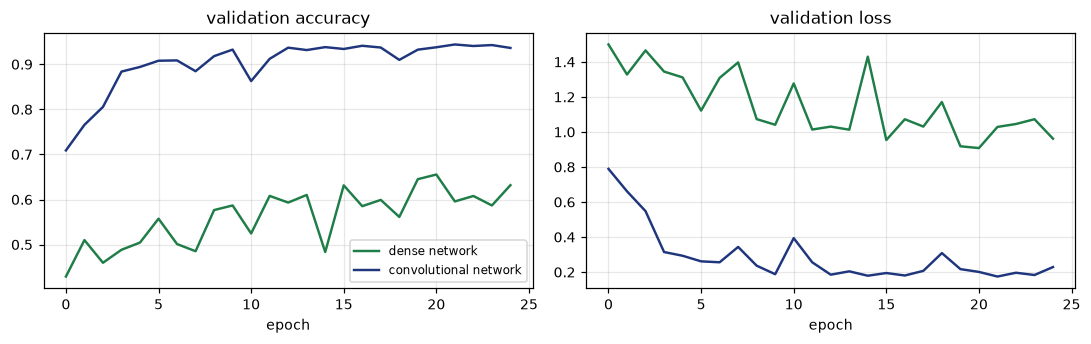

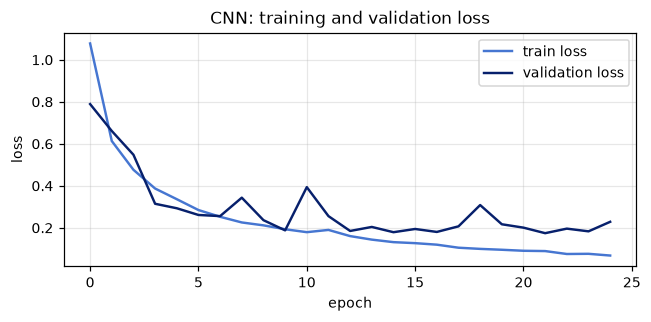

In [ ]:
#Lernkurven des Validierungsdatensatzes (Accuracy und Loss) für beide Modelle darstellen
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for r, color in [(res_dense, "#1f7d48"), (res_cnn, "#1f367d")]:        #r= result, color=Farbe für die Linie
    ax[0].plot(r["hist"].history["val_acc"], color=color, lw=1.6, label=r["tag"])       #r["hist"].history["val_acc"] = Liste der Validierungsgenauigkeit pro Epoche
    ax[1].plot(r["hist"].history["val_loss"], color=color, lw=1.6, label=r["tag"])
ax[0].set_title("validation accuracy"); ax[0].set_xlabel("epoch")
ax[1].set_title("validation loss");     ax[1].set_xlabel("epoch")
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

#Ausgabe des Trainings- und Validierungsfehler des CNN
plt.figure(figsize=(6, 3))
plt.plot(res_cnn["hist"].history["loss"], label="train loss", color="#4676D1", lw=1.6)
plt.plot(res_cnn["hist"].history["val_loss"], label="validation loss", color="#07206C", lw=1.6)
plt.title("CNN: Trainings- und Validierungsfehler")
plt.xlabel("epoch")
plt.ylabel("cross entropy loss")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** Beim Vergleich der beiden Validierungs-Accuracys erkennt man, dass die Accuracy des CNN schnell ansteigt und dann recht stabil bei rund 94 % bleibt. Beim FNN fallen zwei Unterschiede auf. Zum einen verbessert sich die Accuracy weniger stark, zum anderen schwankt sie deutlich stärker als beim CNN. Im rechten Diagramm ist erkennbar, dass das CNN einen deutlich niedrigeren Validierungs-Loss aufweist als das FNN.  

Um zu überprüfen, ob 25 Epochen für das Training des CNN ausreichen, wurden der Trainings- und Validierungs-Loss des CNN in einem Diagramm dargestellt. Hier wird deutlich, dass der Trainings-Loss stetig sinkt. Der Validierungs-Loss nimmt zu Beginn stark ab und pendelt sich um 0,2 ein. Das bedeutet, dass das Netzwerk sich weiter an die Trainingsdaten anpasst, sich auf den Validierungsdaten aber nur noch wenig verbessert. Mehr Epochen könnten daher das Risiko für Overfitting erhöhen.

Schwächste Klasse in dense network: 6 · normal colon mucosa  (recall 0.166)
am häufigsten verwechselt mit: colorectal adenocarcinoma epithelium
Schwächste Klasse in convolutional network: 7 · cancer-associated stroma  (recall 0.591)
am häufigsten verwechselt mit: debris


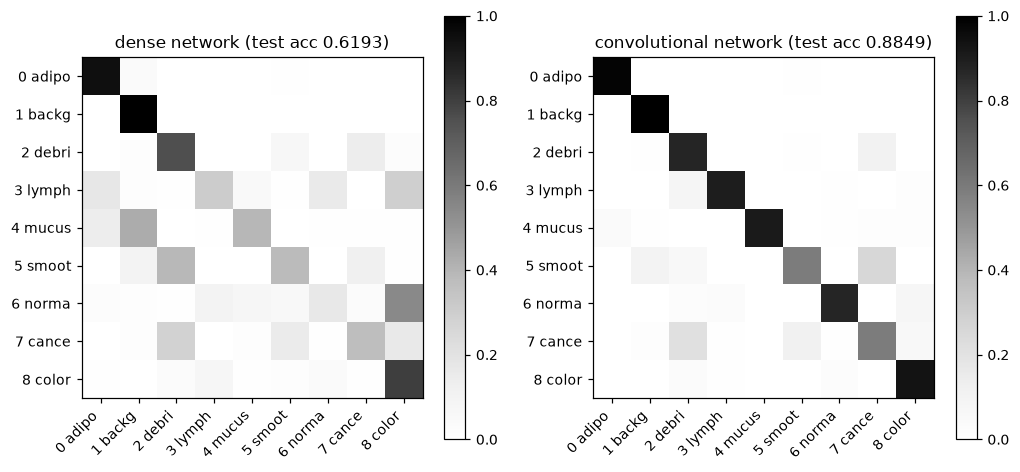

In [ ]:
#Darstellung der Konfusionsmatrix für beide Modelle
test_labels = y_test.ravel()        # Labels von Testset eindimensional machen

# Klassennummern und Namen in der richtigen Reihenfolge
class_ids = range(len(class_labels))
class_names = [class_labels[str(i)] for i in class_ids]
short_names = [f"{i} {name[:5]}" for i, name in enumerate(class_names)]     #Nummer und Name (5 Buchstaben)

# Zwei Plotbereiche nebeneinander erstellen
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for result, ax in zip((res_dense, res_cnn), axes):        #zip = zwei Listen parallel durchlaufen -> ax= Achsenabschnitt (links oder rechts)
    cm = confusion_matrix(test_labels, result["pred"], labels=class_ids)        #cm = Konfusionsmatrix
    cm_normalized = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]     #Normalisierte Konfusionsmatrix -> pro Zeile (pro Klasse) auf 1 normiert
    im = ax.imshow(cm_normalized, cmap="Greys", vmin=0, vmax=1)       #Darstellung der Normalisierten Konfusionsmatrix als Bild
    
    ax.set_title(f"{result['tag']} (test acc {result['acc']:.4f})")
    ax.set_xticks(class_ids); ax.set_xticklabels(short_names, rotation=45, ha="right")
    ax.set_yticks(class_ids); ax.set_yticklabels(short_names)
    ax.grid(False)
    plt.colorbar(im, ax=ax)

    per_class = cm.diagonal() / cm.sum(1)

    worst = per_class.argmin() 
    print(f"Schwächste Klasse in {result['tag']}: {worst} · {class_names[worst]}  (recall {per_class[worst]:.3f})")
    
    mistakes = cm[worst].copy()     #vorhersagen der schwächsten horizontalen Klasse 
    mistakes[worst] = 0     #die korrekten Vorhersagen der schwächsten Klasse auf 0 setzen -> wenn man dann argmax sucht hat man die klasse die am häufigsten mit der richtigen Klasse verwechselt wird
    confused_with = mistakes.argmax()      #Index der Klasse, mit der die schwächste Klasse am häufigsten verwechselt wird   
    print(f"am häufigsten verwechselt mit: {class_names[confused_with]}")




**WH Recall:** „Von allen Bildern, die tatsächlich zu dieser Klasse gehören, wie viele hat das Modell richtig erkannt?“  
Im FNN hat die Klasse 6 einen Recall von 0.166, das bedeutet, dass 16,6 % der Bilder mit normaler Darmschleimhaut richtig erkannt wurden. Die meisten der Bilder wurden fälschlicherweise als colorectal adenocarcinoma epithelium klassifiziert.  
Im Vergleich dazu schneidet das CNN bereits besser ab.